In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
conn = sqlite3.connect("indian_business.db")

print("Database connected successfully!")

Database connected successfully!


In [5]:
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print("Available tables:")
display(tables)

Available tables:


,name
0,businesses
1,owners


In [7]:
df = pd.read_sql_query("SELECT * FROM businesses", conn)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,Business_ID,Business_Name,City
0,101,FreshMart,Bangalore
1,102,TechZone,Mumbai
2,103,GreenLeaf,Chennai
3,104,Cafe Aroma,Bangalore
4,105,StyleHub,Hyderabad


In [9]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Business_ID    5 non-null      int64
 1   Business_Name  5 non-null      str  
 2   City           5 non-null      str  
dtypes: int64(1), str(2)
memory usage: 252.0 bytes


In [11]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 5
Number of columns: 3
Dataset shape: (5, 3)


In [15]:
print("Statistical summary:")
display(df.describe(include="all"))

Statistical summary:


,Business_ID,Business_Name,City
count,5.000000,5,5
unique,NaN,5,4
top,NaN,FreshMart,Bangalore
freq,NaN,1,2
mean,103.000000,NaN,NaN
std,1.581139,NaN,NaN
min,101.000000,NaN,NaN
25%,102.000000,NaN,NaN
50%,103.000000,NaN,NaN
75%,104.000000,NaN,NaN


In [17]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Business_ID      0
Business_Name    0
City             0
dtype: int64


In [19]:
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [21]:
city_counts = df.groupby(df.columns[2]).size()

print("Number of businesses in each city:")
print(city_counts)

Number of businesses in each city:
City
Bangalore    2
Chennai      1
Hyderabad    1
Mumbai       1
dtype: int64


In [23]:
city_counts = df.groupby(df.columns[2]).size()

top_city = city_counts.idxmax()
top_count = city_counts.max()

print("City with the most businesses:", top_city)
print("Number of businesses:", top_count)

City with the most businesses: Bangalore
Number of businesses: 2


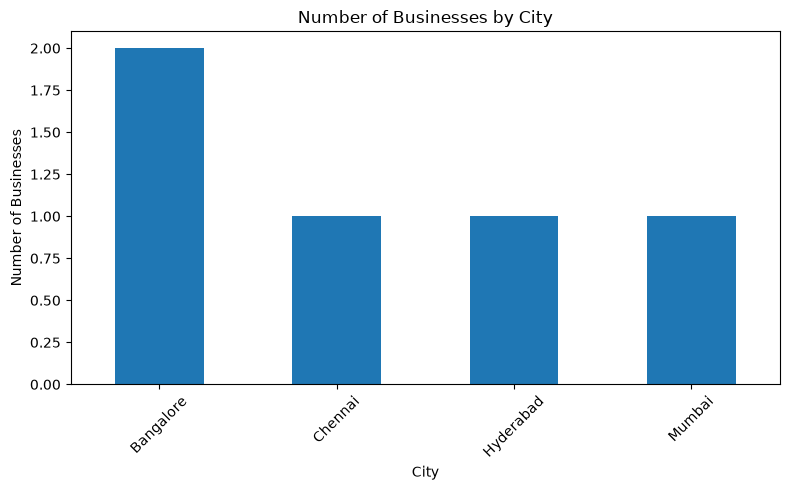

In [25]:
plt.figure(figsize=(8, 5))

city_counts.plot(kind="bar")

plt.title("Number of Businesses by City")
plt.xlabel("City")
plt.ylabel("Number of Businesses")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

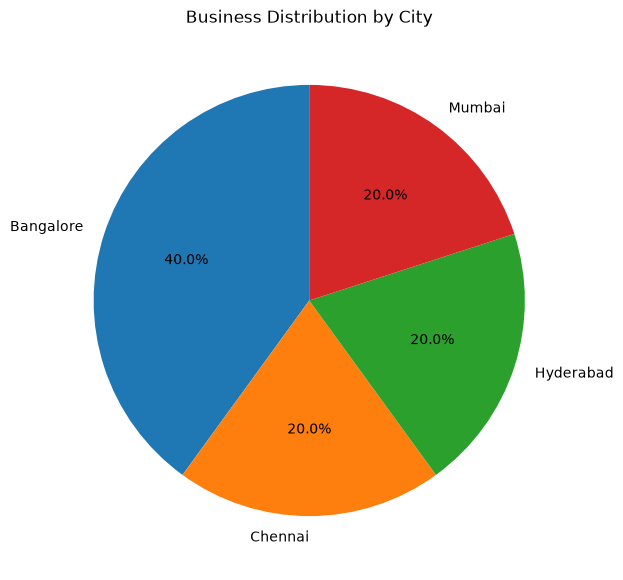

In [27]:
plt.figure(figsize=(7, 7))

city_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Business Distribution by City")
plt.ylabel("")

plt.show()

In [29]:
print("All business names:")

for name in df.iloc[:, 1]:
    print(name)

All business names:
FreshMart
TechZone
GreenLeaf
Cafe Aroma
StyleHub


In [31]:
print("========== EDA SUMMARY ==========")

print("Total businesses:", len(df))
print("Total cities:", df.iloc[:, 2].nunique())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("Top city:", city_counts.idxmax())
print("Businesses in top city:", city_counts.max())

print("================================")

========== EDA SUMMARY ==========
Total businesses: 5
Total cities: 4
Missing values: 0
Duplicate rows: 0
Top city: Bangalore
Businesses in top city: 2


In [33]:
city_summary = city_counts.reset_index()

city_summary.columns = ["City", "Business_Count"]

city_summary.to_csv("W2D3_City_EDA_Summary.csv", index=False)

print("EDA summary saved successfully!")
display(city_summary)

EDA summary saved successfully!


,City,Business_Count
0,Bangalore,2
1,Chennai,1
2,Hyderabad,1
3,Mumbai,1


In [35]:
import os

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print(
    "EDA CSV exists:",
    os.path.exists("W2D3_City_EDA_Summary.csv")
)

Dataset shape: (5, 3)
Missing values: 0
Duplicate rows: 0
EDA CSV exists: True
